# Rainbows and glories

A rainbow is sunlight that has been refracted into a raindrop, reflected
inside it once (primary bow) or twice (secondary bow) and refracted out
again. Descartes traced rays through a glass globe in 1637 and found that
the outgoing angle has an extremum: many rays leave in nearly the same
direction, about 42° from the antisolar point (the shadow of the
observer's head), and the drops on a cone of that angle around the
antisolar point light up. Newton added the colours: water disperses, so each
wavelength has its own cone. But geometric optics predicts an infinitely
bright edge and nothing beyond it, and it cannot explain the pale pink and
green **supernumerary** fringes often seen inside the primary bow. Airy
(1838) treated the bow as a caustic of a cubic wavefront and found the
Airy function; Lorenz and Mie (1890, 1908) solved the scattering by a
sphere exactly.

This notebook goes from rays to waves and from monochromatic intensities
to the colours we see:

1. where the bows are, and the dispersion of water: Descartes' angles,
   their wavelength dependence, the width of the bows,
2. exact ray traces through a drop (also with the sequential ray tracer),
   the deviation as a function of the impact parameter, Alexander's dark
   band, and the cubic wavefront at the caustic,
3. the geometric intensity of all orders, against a Monte Carlo of traced
   rays, and the polarization of the bows,
4. the colours of the geometric rainbow, with the solar spectrum and the
   size of the Sun's disc,
5. Airy theory against Lorenz-Mie theory: the supernumeraries and their
   $a^{-2/3}$ scaling, and where Airy fails,
6. the colours of real bows for drops from 0.25 mm to 15 µm: the
   supernumeraries and the white fogbow,
7. the glory, coloured rings around the shadow of an aircraft on a
   cloud, which no ray picture explains.

The tools are in `pyoptics.rainbow` (Descartes' angles, the drop ray trace,
geometric and Airy cross sections, the drop as a sequential
`raytrace.System`), `analytical.mie_amplitudes()` (the far field of
the Lorenz-Mie series of notebooks [64](64_fdtd_3d_nanojet.ipynb) and
[66](66_fdfd_basics.ipynb)), `materials.water_index()` and
`materials.air_index()` for the dispersion, and `pyoptics.colour` for the
CIE colour matching functions (those of notebook
[10](10_interfaces_thin_films.ipynb), section 4.1). Lengths are in mm.
Angles are given either as the **scattering angle** $\theta$ between the
sunlight and the scattered light (0 forward, 180° straight back) or, as
seen in the sky, as the angle $\rho = 180° - \theta$ from the antisolar
point.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
from scipy.special import ai_zeros, jv

from pyoptics import colour, rainbow, sketch
from pyoptics.analytical import mie_amplitudes
from pyoptics.materials import air_index, water_index
from pyoptics.raytrace import Rays

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "image.origin": "lower"})
t_start = time.time()
DEG = np.pi/180


def n_drop(wl_nm):
    # index of a water drop relative to the surrounding air
    return water_index(wl_nm)/air_index(wl_nm)


WL = 550e-6                         # mm
N550 = n_drop(550.0)
K550 = 2*np.pi/WL
LAM = np.arange(380.0, 731.0, 10.0)  # wavelengths for the colours (nm)
SUN = colour.planck(LAM, 5800.0)     # the Sun as a black body
SUN_RADIUS = 0.266*DEG               # angular radius of the solar disc
ORDERS = (-1, 0, 1, 2, 3, 4)         # external reflection, transmission, 1 to 4 reflections
ORDER_NAMES = {-1: "reflection", 0: "transmission", 1: "primary (k = 1)", 2: "secondary (k = 2)",
               3: "k = 3", 4: "k = 4"}
ORDER_COLOURS = {-1: "0.45", 0: "#8c6d31", 1: "#2a7ab9", 2: "#d6604d", 3: "#5aa469", 4: "#8e5ba8"}


def sun_disc(theta, I):
    # convolve I(theta) (last axis, uniform grid) with the brightness profile of the solar disc
    d = theta[1] - theta[0]
    m = int(np.ceil(SUN_RADIUS/abs(d)))
    u = np.arange(-m, m + 1)*d
    w = np.sqrt(np.clip(1 - (u/SUN_RADIUS)**2, 0, None))
    w /= w.sum()
    I = np.asarray(I, dtype=float)
    return np.apply_along_axis(lambda v: np.convolve(v, w, mode="same"), -1, I)


def rgb_of(I_lam, gain, background=None):
    # sRGB of spectra I_lam (wavelength along axis 0, LAM) lit by the Sun, on a background
    lin = gain*colour.xyz_to_linear_srgb(colour.spectrum_to_xyz(LAM, I_lam*SUN[:, None], axis=0))
    if background is not None:
        lin = lin + np.asarray(background)
    lin = lin - np.minimum(lin.min(axis=-1, keepdims=True), 0)    # out of gamut: add white
    return colour.srgb_gamma(lin)


def sky_image(rho, rgb_lin, sun_elevation=20.0, width=110, height=50, n=360,
              background=(0.10, 0.12, 0.16)):
    # view of the sky (azimuth, elevation in deg) with a profile rgb_lin(rho) around the
    # antisolar point, which lies sun_elevation below the horizon
    az = np.linspace(-width/2, width/2, n)*DEG
    el = np.linspace(0, height, int(n*height/width))*DEG
    AZ, EL = np.meshgrid(az, el)
    v = np.stack([np.cos(EL)*np.sin(AZ), np.sin(EL), np.cos(EL)*np.cos(AZ)], -1)
    h = sun_elevation*DEG
    anti = np.array([0.0, -np.sin(h), np.cos(h)])
    r = np.arccos(np.clip(v @ anti, -1, 1))
    img = np.stack([np.interp(r, rho, c, left=c[0], right=c[-1]) for c in rgb_lin.T], -1)
    img = img + np.asarray(background)
    img = img - np.minimum(img.min(axis=-1, keepdims=True), 0)
    return colour.srgb_gamma(img), (az[0]/DEG, az[-1]/DEG, 0, height)

## 1. Where the bows are

The sketch shows the geometry. The Sun is behind the observer, at an
elevation $h$; the line from the Sun through the eye ends at the
antisolar point, $h$ below the horizon. A drop sends its light to the eye
at the angle $\rho$ from this line, so all drops that look the same lie on a
cone around it: every observer has a rainbow of their own, and the bow is
a circle around the antisolar point, of which the part above the horizon
is seen. The cone of the primary bow has a half angle of about 42°, that
of the secondary bow about 51°. Between them the sky is darker:
Alexander's dark band (Alexander of Aphrodisias, around 200 AD).

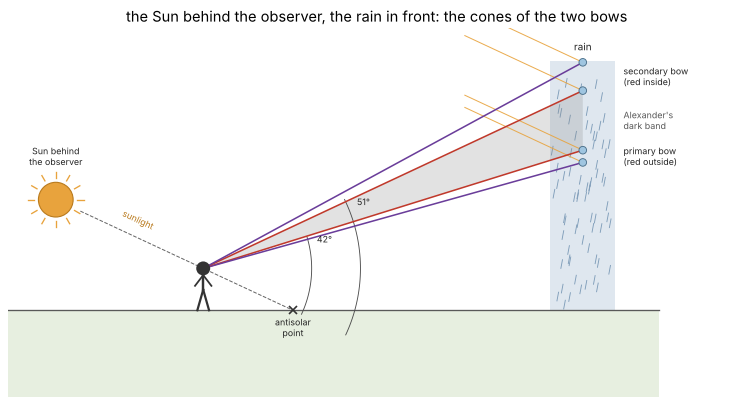

In [2]:
fig, ax = plt.subplots(figsize=(12, 5.2))
sketch.rainbow_observer(ax, title="the Sun behind the observer, the rain in front: the cones of the two bows")
plt.tight_layout()

### Descartes' angle and the dispersion of water

A ray with the impact parameter $b = a\sin i$ on a drop of radius $a$ is
refracted to the angle $r$, $\sin i = n\sin r$. After $k$ internal
reflections, each again at the angle $r$, it has been turned by

$$D_k(i) = k\pi + 2i - 2(k+1)r .$$

The rainbow ray is the one where $D_k$ is stationary,
$\mathrm dD_k/\mathrm di = 2 - 2(k+1)\,\mathrm dr/\mathrm di = 0$, which with
$\mathrm dr/\mathrm di = \cos i/(n\cos r)$ gives Descartes' result

$$\cos^2 i_c = \frac{n^2 - 1}{k(k+2)} .$$

How much the angle of the bow changes with the index follows without any
differentiation of $i_c(n)$: since $\partial D/\partial i = 0$ there, only
the explicit dependence through $r$ counts (the envelope theorem),

$$\frac{\mathrm dD_c}{\mathrm dn} = -2(k+1)\frac{\partial r}{\partial n}
  = \frac{2(k+1)\tan r_c}{n} .$$

The index of the drop is that of water, relative to the surrounding air:
`materials.water_index()` is the Sellmeier formula of Daimon and Masumura
(20 °C, relative to vacuum, $n = 1.33335$ at 589.3 nm) and
`materials.air_index()` Ciddor's standard air ($1.000277$), which together
give the textbook $n_D = 1.33298$.

line              lambda   n_water/air   primary rho   secondary rho   (deg from the antisolar point)
violet (h line)   404.66   1.34274       40.68          53.41
blue (F)          486.13   1.33712       41.48          51.96
green (e)         546.07   1.33446       41.87          51.27
yellow (D)        589.29   1.33298       42.08          50.89
red (C)           656.27   1.33114       42.35          50.40

width of the bows from 400 to 700 nm: primary 1.87 deg, secondary 3.38 deg


k = 1: extremum of the traced rays 138.11239 deg, Descartes 138.11239 deg


k = 2: extremum of the traced rays 128.76578 deg, Descartes 128.76578 deg


k = 3: extremum of the traced rays 41.25535 deg, Descartes 41.25535 deg
k = 1: |dtheta_c/dn| finite difference 2.52787, 2(k+1) tan(r_c)/n = 2.52787 rad
k = 2: |dtheta_c/dn| finite difference 4.55904, 2(k+1) tan(r_c)/n = 4.55904 rad


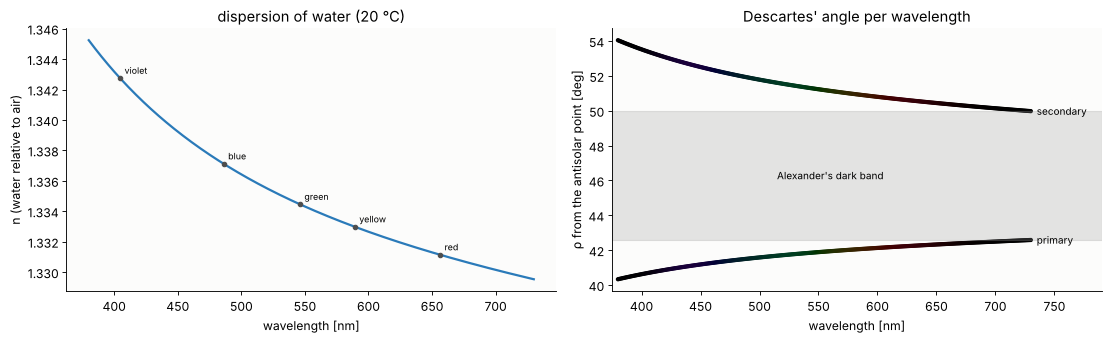

In [3]:
lines = {"violet (h line)": 404.66, "blue (F)": 486.13, "green (e)": 546.07, "yellow (D)": 589.29,
         "red (C)": 656.27}
print("line              lambda   n_water/air   primary rho   secondary rho   (deg from the antisolar point)")
for name, l in lines.items():
    n = n_drop(l)
    print("{:16s} {:7.2f}   {:.5f}      {:6.2f}         {:6.2f}".format(
        name, l, n, 180 - rainbow.descartes(n, 1)[2]/DEG, 180 - rainbow.descartes(n, 2)[2]/DEG))

lam = np.linspace(380, 730, 351)
n = n_drop(lam)
rho1 = 180 - rainbow.descartes(n, 1)[2]/DEG
rho2 = 180 - rainbow.descartes(n, 2)[2]/DEG
print("\nwidth of the bows from 400 to 700 nm: primary {:.2f} deg, secondary {:.2f} deg".format(
    np.interp(700, lam, rho1) - np.interp(400, lam, rho1), np.interp(400, lam, rho2) - np.interp(700, lam, rho2)))

# the minimum of the traced deviation against Descartes' formula
b = np.linspace(0, 1, 400001)[1:-1]
for k in (1, 2, 3):
    th = rainbow.trace_drop(0*b, b, N550, k).theta
    ext = th[np.argmin(np.abs(np.gradient(th)))]     # where theta(b) is stationary
    print("k = {}: extremum of the traced rays {:.5f} deg, Descartes {:.5f} deg".format(
        k, ext/DEG, rainbow.descartes(N550, k)[2]/DEG))

# envelope theorem: dD_c/dn against a finite difference of Descartes' formula
for k in (1, 2):
    _, r_c, _ = rainbow.descartes(N550, k)
    dn = 1e-6
    fd = abs(rainbow.descartes(N550 + dn, k)[2] - rainbow.descartes(N550 - dn, k)[2])/(2*dn)
    print("k = {}: |dtheta_c/dn| finite difference {:.5f}, 2(k+1) tan(r_c)/n = {:.5f} rad".format(
        k, fd, 2*(k + 1)*np.tan(r_c)/N550))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
ax.plot(lam, n, color="#2a7ab9", lw=2)
for name, l in lines.items():
    ax.plot(l, n_drop(l), "o", color="0.3", ms=4)
    ax.annotate(name.split()[0], (l, n_drop(l)), textcoords="offset points", xytext=(4, 4), fontsize=8)
ax.set_xlabel("wavelength [nm]"); ax.set_ylabel("n (water relative to air)")
ax.set_title("dispersion of water (20 °C)")
ax = axes[1]
strip = colour.spectrum_to_rgb(lam, np.eye(len(lam)), gain=2.2, desaturate=True)
for k, rho in ((1, rho1), (2, rho2)):
    ax.scatter(lam, rho, c=strip, s=8)
    ax.text(lam[-1] + 5, rho[-1], ["", "primary", "secondary"][k], va="center", fontsize=9)
ax.axhspan(rho1.max(), rho2.min(), color="0.6", alpha=0.25)
ax.text(560, (rho1.max() + rho2.min())/2, "Alexander's dark band", ha="center", va="center", fontsize=9)
ax.set_xlabel("wavelength [nm]"); ax.set_ylabel("ρ from the antisolar point [deg]")
ax.set_title("Descartes' angle per wavelength"); ax.set_xlim(375, 790)
plt.tight_layout()

Red ($\lambda = 656$ nm) leaves the primary bow at 42.3°, violet at
40.6°: the primary bow is red outside and about 1.8° wide, more than three
times the diameter of the Sun. In the secondary bow the light is reflected
once more and the order of the colours is reversed; its larger
$\mathrm dD_c/\mathrm dn$ (factor $(k+1)\tan r_c$) makes it almost twice as
wide. The extrema of the traced deviations agree with Descartes' formula,
and the finite difference with the envelope theorem.

## 2. Rays through a drop

`rainbow.trace_drop()` traces rays parallel to the axis exactly through
a sphere: intersections, the vector law of refraction and reflection, any
number $k$ of internal reflections. On the left, rays of the primary bow,
coloured by their impact parameter; the thick ray is Descartes' rainbow
ray. Rays with a smaller and a larger impact parameter leave on both sides
of it and turn back towards it: no ray of the primary order leaves the drop
at less than $\theta_c$ (more than 42° from the antisolar point is dark in
first order). The secondary rays (middle) cross inside the drop and leave
at most at 129°.

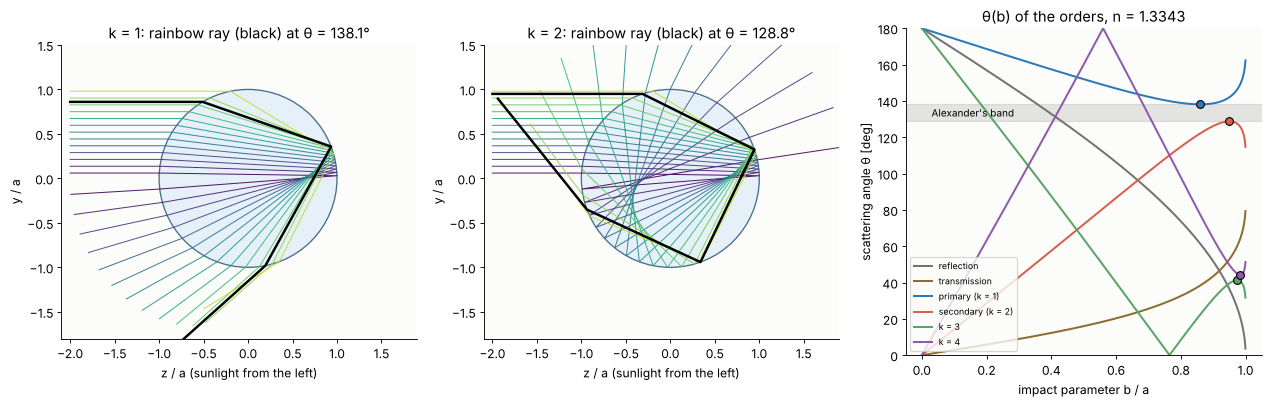

In [4]:
def draw_drop(ax, k, n=N550, n_rays=13, a=1.0):
    ax.add_patch(plt.Circle((0, 0), a, facecolor="#e6f0f8", edgecolor="#4a6f8a", lw=1.2))
    b = np.linspace(0.06, 0.98, n_rays)
    tr = rainbow.trace_drop(0*b, b, n, k, a)
    cols = plt.cm.viridis(np.linspace(0, 0.9, n_rays))
    for j in range(n_rays):
        P = tr.points[:, j]
        ax.plot(P[:, 2], P[:, 1], color=cols[j], lw=0.9, alpha=0.9)
    b_c = rainbow.airy_parameters(n, k, a)[1]
    tr_c = rainbow.trace_drop(0.0, b_c, n, k, a)
    P = tr_c.points[:, 0].copy()
    P[-1] = P[-2] + 1.6*a*tr_c.directions[0]
    ax.plot(P[:, 2], P[:, 1], color="k", lw=2.2)
    ax.set_aspect("equal"); ax.set_xlim(-2.1, 1.9); ax.set_ylim(-1.8, 1.5)
    ax.set_xlabel("z / a (sunlight from the left)"); ax.set_ylabel("y / a")
    th_c = rainbow.descartes(n, k)[2]
    ax.set_title("k = {}: rainbow ray (black) at θ = {:.1f}°".format(k, th_c/DEG))


fig, axes = plt.subplots(1, 3, figsize=(16, 5.2))
draw_drop(axes[0], 1)
draw_drop(axes[1], 2)
ax = axes[2]
bb = np.linspace(0, 1, 2001)[1:-1]
for k in ORDERS:
    th = rainbow.scattering_angle(np.arcsin(bb), N550, k)
    ax.plot(bb, th/DEG, color=ORDER_COLOURS[k], lw=1.8, label=ORDER_NAMES[k])
    if k >= 1:
        th_c, b_c, _ = rainbow.airy_parameters(N550, k)
        ax.plot(b_c, th_c/DEG, "o", color=ORDER_COLOURS[k], ms=7, mec="k")
t1, t2 = rainbow.descartes(N550, 1)[2], rainbow.descartes(N550, 2)[2]
ax.axhspan(t2/DEG, t1/DEG, color="0.6", alpha=0.25)
ax.text(0.03, (t1 + t2)/2/DEG, "Alexander's band", va="center", fontsize=9)
ax.set_xlabel("impact parameter b / a"); ax.set_ylabel("scattering angle θ [deg]")
ax.set_title("θ(b) of the orders, n = {:.4f}".format(N550))
ax.legend(fontsize=8, loc="lower left"); ax.set_ylim(0, 180)
plt.tight_layout()

The right panel has all orders. The external reflection (grey) and the
directly transmitted light (brown) cover their angles monotonically, every
$k \ge 1$ has a turning point, the rainbow ray (dots). Between 129° and
138° neither $k = 1$ nor $k = 2$ sends any light: only the reflection and the
weak higher orders reach Alexander's band, which is why it is darker than
the sky inside the primary bow (lit by all primary rays that are not
rainbow rays) and outside the secondary bow. The third order bow has its
turning point at $\theta \approx 42°$, i.e. 42° around the **Sun**, where
it is lost in the glare of the forward scattered light.

### The drop as a sequential system

The sequential ray tracer of `pyoptics.raytrace` intersects a sphere only on
the hemisphere around its vertex. A drop then needs one surface per
intersection, each tilted about $x$ such that the next intersection lies
on its vertex hemisphere and the previous one does not:
`rainbow.drop_system()` builds this for a band of impact parameters. The
traced directions agree with the direct trace to rounding:

In [5]:
for k in (1, 2, 3):
    err, n_rays = 0.0, 0
    for i_band in np.arange(5, 90, 10)*DEG:
        i = i_band + np.linspace(-5, 5, 21)*DEG
        b = np.sin(i[(i > 0) & (i < np.pi/2)])
        system = rainbow.drop_system(1.0, n_drop, k, i_band, wavelength=WL)
        rays = Rays(np.stack([0*b, b, np.full_like(b, -2.0)], -1), np.tile([0, 0, 1.0], (len(b), 1)), 0*b)
        bundle = system.trace(rays, clip=False)
        direct = rainbow.trace_drop(0*b, b, N550, k)
        err = max(err, np.abs(bundle.directions[-2] - direct.directions).max())
        n_rays += len(b)
    print("k = {}: {} rays, largest difference of the outgoing directions {:.1e}".format(k, n_rays, err))
print(system.surfaces[1])

k = 1: 187 rays, largest difference of the outgoing directions 3.5e-12
k = 2: 187 rays, largest difference of the outgoing directions 4.7e-12
k = 3: 187 rays, largest difference of the outgoing directions 1.1e-11
Mirror(R=1.0, thickness=-1.285875722510149, n_after=None, material=None, conic=0.0, aspheric=(), semi_diameter=None)


### The caustic and Airy's cubic wavefront

Near the rainbow ray the outgoing angle is quadratic in the impact
parameter, $\theta(b) \approx \theta_c + \tfrac12\theta''_c(b - b_c)^2$
(`rainbow.airy_parameters()`). The wavefront, whose normal is the ray,
has the slope $\theta - \theta_c$ and therefore the shape of a **cubic**,
$w(s) = \theta''_c s^3/6$, with an inflection at the rainbow ray ($s$ is the
distance from it across the wavefront; at the rainbow ray
$\mathrm ds/\mathrm db = 1$). The rays on both sides of the inflection
are parallel to the rainbow ray at the same angle: the rays of the two
branches cross, and their envelope, the caustic, runs off to infinity
along the rainbow ray. Below, the outgoing rays near the rainbow ray, the
wavefront at a fixed optical path, and the cubic fit to the traced
wavefront.

theta''_c = 9.7249 /a^2: cubic coefficient fitted 1.6230, theta''/6 = 1.6208


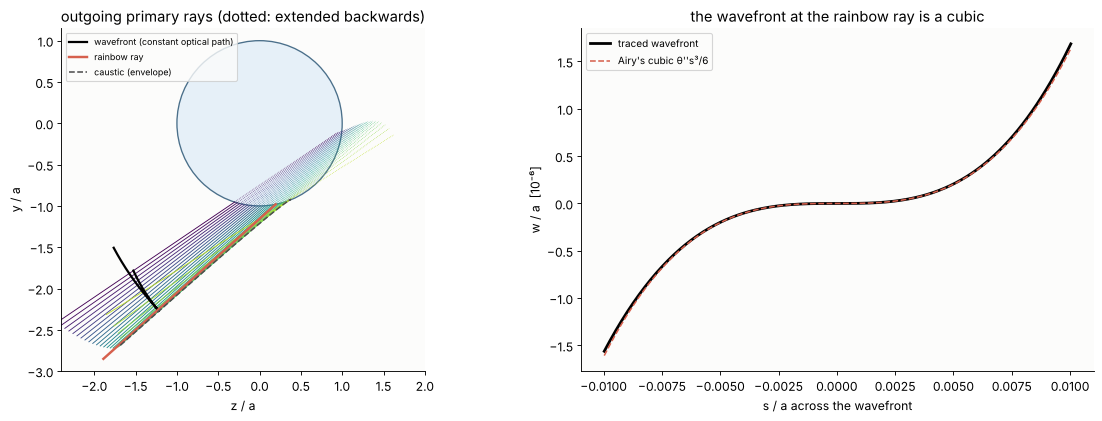

In [6]:
th_c, b_c, th2 = rainbow.airy_parameters(N550, 1)
b = np.linspace(0.62, 0.98, 25)
tr = rainbow.trace_drop(0*b, b, N550, 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={"width_ratios": [1.25, 1]})
ax = axes[0]
ax.add_patch(plt.Circle((0, 0), 1, facecolor="#e6f0f8", edgecolor="#4a6f8a", lw=1.2))
cols = plt.cm.viridis((b - b[0])/(b[-1] - b[0])*0.9)
for j in range(len(b)):
    X, d = tr.points[-2, j], tr.directions[j]
    ax.plot([X[2], X[2] + 2.6*d[2]], [X[1], X[1] + 2.6*d[1]], color=cols[j], lw=0.8)
    ax.plot([X[2], X[2] - 1.5*d[2]], [X[1], X[1] - 1.5*d[1]], color=cols[j], lw=0.6, ls=":")
# wavefront at a fixed optical path
bw = np.linspace(0.5, 0.995, 400)
trw = rainbow.trace_drop(0*bw, bw, N550, 1)
L0 = np.nanmax(trw.opl) + 1.4
W = trw.points[-2] + (L0 - trw.opl)[:, None]*trw.directions
ax.plot(W[:, 2], W[:, 1], color="k", lw=2, label="wavefront (constant optical path)")
trc = rainbow.trace_drop(0.0, b_c, N550, 1)
Xc, dc = trc.points[-2, 0], trc.directions[0]
ax.plot([Xc[2], Xc[2] + 2.8*dc[2]], [Xc[1], Xc[1] + 2.8*dc[1]], color="#d6604d", lw=2.2,
        label="rainbow ray")
# envelope of the outgoing rays (caustic), with the virtual part inside / behind the drop
bb = np.linspace(0.3, 0.995, 3000)
tt = rainbow.trace_drop(0*bb, bb, N550, 1)
X, d = tt.points[-2][:, 1:], tt.directions[:, 1:]
dX, dd = np.gradient(X, bb, axis=0), np.gradient(d, bb, axis=0)
cross = lambda u, v: u[:, 0]*v[:, 1] - u[:, 1]*v[:, 0]
t_env = -cross(dX, d)/cross(dd, d)
E = X + t_env[:, None]*d
keep = (t_env > -1.6) & (t_env < 2.6)
ax.plot(E[keep, 1], E[keep, 0], color="0.3", lw=1.4, ls="--", label="caustic (envelope)")
ax.set_aspect("equal"); ax.set_xlim(-2.4, 2.0); ax.set_ylim(-3.0, 1.15)
ax.set_xlabel("z / a"); ax.set_ylabel("y / a"); ax.legend(fontsize=8, loc="upper left")
ax.set_title("outgoing primary rays (dotted: extended backwards)")

ax = axes[1]
# the wavefront in the frame of the rainbow ray
bw = b_c + np.linspace(-0.01, 0.01, 401)
trw = rainbow.trace_drop(0*bw, bw, N550, 1)
W = trw.points[-2] + (5.0 - trw.opl)[:, None]*trw.directions
Wc = W[200]; nperp = np.array([0.0, dc[2], -dc[1]])
s, w = (W - Wc) @ nperp, (W - Wc) @ dc
c3 = np.polyfit(s, w, 3)
ax.plot(s, w*1e6, color="k", lw=2.5, label="traced wavefront")
ax.plot(s, th2*s**3/6*1e6, color="#d6604d", lw=1.4, ls="--", label="Airy's cubic θ''s³/6")
ax.set_xlabel("s / a across the wavefront"); ax.set_ylabel("w / a  [10⁻⁶]")
ax.set_title("the wavefront at the rainbow ray is a cubic"); ax.legend(fontsize=9)
print("theta''_c = {:.4f} /a^2: cubic coefficient fitted {:.4f}, theta''/6 = {:.4f}".format(th2, c3[0], th2/6))
plt.tight_layout()

The traced wavefront is Airy's cubic. The dashed envelope of the
outgoing rays is the caustic: a fold that touches the rays of both
branches and approaches the rainbow ray, so in the far field all its
light ends up at $\theta_c$, where geometric optics gives infinite
intensity. Airy's diffraction integral over the cubic wavefront (section
5) removes the infinity.

## 3. How bright the bows are: the geometric intensity

A ring of impact parameters $b \ldots b + \mathrm db$ carries the power
$2\pi b\,\mathrm db$ (per unit incident irradiance) into the solid angle
$2\pi\sin\theta\,|\mathrm d\theta|$, which gives the differential cross
section of one branch

$$\frac{\mathrm d\sigma}{\mathrm d\Omega} = \frac{b}{\sin\theta}
  \left|\frac{\mathrm db}{\mathrm d\theta}\right| \varepsilon,
  \qquad \varepsilon_{s,p} = T(i)\,R(r)^k\,T(r)$$

with the Fresnel power factors $\varepsilon$ (from `pyoptics.interfaces`)
for light polarized perpendicular (s) or parallel (p) to the scattering
plane; every ray stays in its plane of incidence, which is the scattering
plane. It diverges like $|\theta - \theta_c|^{-1/2}$ at the bow.
`rainbow.geometric_cross_section()` sums the branches. Below it is
compared with a Monte Carlo of 4 million rays traced with
`trace_drop()` (impact parameters uniform over the drop's cross
section, each weighted with its $\varepsilon$, binned by the outgoing angle).

k = 1: degree of polarization of the rainbow ray 0.926
k = 2: degree of polarization of the rainbow ray 0.809
internal angle of the primary rainbow ray 40.1 deg, internal Brewster angle 36.8 deg
sky 30 deg from the antisolar point: 0.0667 a^2/sr, in Alexander's band (46.5 deg): 0.0052 a^2/sr, ratio 12.8
55 deg from the antisolar point: 0.0207 a^2/sr, 4.0 times the band


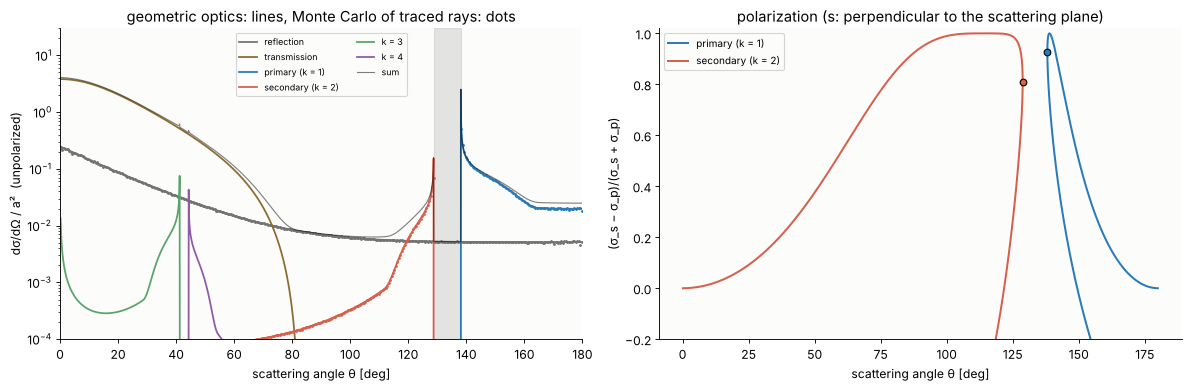

In [7]:
rng = np.random.default_rng(1)
N_mc = 4_000_000
b_mc = np.sqrt(rng.uniform(0, 1, N_mc))
phi = rng.uniform(0, 2*np.pi, N_mc)
x_mc, y_mc = b_mc*np.cos(phi), b_mc*np.sin(phi)
edges = np.linspace(0, np.pi, 361)
centres = (edges[:-1] + edges[1:])/2
d_omega = 2*np.pi*(np.cos(edges[:-1]) - np.cos(edges[1:]))
theta = np.linspace(0.2, 179.8, 3000)*DEG

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
ax = axes[0]
total = 0
for k in ORDERS:
    s_s, s_p = rainbow.geometric_cross_section(N550, k, theta=theta)
    ax.semilogy(theta/DEG, (s_s + s_p)/2, color=ORDER_COLOURS[k], lw=1.6, label=ORDER_NAMES[k])
    total = total + (s_s + s_p)/2
    if k in (-1, 1, 2):
        tr = rainbow.trace_drop(x_mc, y_mc, N550, k)
        hist, _ = np.histogram(tr.theta, edges, weights=(tr.eps_s + tr.eps_p)/2)
        ax.semilogy(centres/DEG, hist*np.pi/N_mc/d_omega, ".", color=ORDER_COLOURS[k], ms=3)
ax.semilogy(theta/DEG, total, color="k", lw=1, alpha=0.5, label="sum")
ax.axvspan(t2/DEG, t1/DEG, color="0.6", alpha=0.25)
ax.set_ylim(1e-4, 30); ax.set_xlim(0, 180)
ax.set_xlabel("scattering angle θ [deg]"); ax.set_ylabel("dσ/dΩ / a²  (unpolarized)")
ax.set_title("geometric optics: lines, Monte Carlo of traced rays: dots")
ax.legend(fontsize=8, ncol=2)

# polarization of the bows
ax = axes[1]
for k in (1, 2):
    i = np.linspace(0.001, np.pi/2 - 0.001, 4000)
    th, s_s, s_p = rainbow.geometric_cross_section(N550, k, i=i)
    ax.plot(th/DEG, (s_s - s_p)/(s_s + s_p), color=ORDER_COLOURS[k], lw=1.8, label=ORDER_NAMES[k])
    eps_s, eps_p = rainbow.fresnel_factors(np.arcsin(rainbow.airy_parameters(N550, k)[1]), N550, k)
    P = (eps_s - eps_p)/(eps_s + eps_p)
    ax.plot(rainbow.descartes(N550, k)[2]/DEG, P, "o", color=ORDER_COLOURS[k], mec="k")
    print("k = {}: degree of polarization of the rainbow ray {:.3f}".format(k, P))
r_c = rainbow.descartes(N550, 1)[1]
print("internal angle of the primary rainbow ray {:.1f} deg, internal Brewster angle {:.1f} deg".format(
    r_c/DEG, np.arctan(1/N550)/DEG))
ax.set_xlabel("scattering angle θ [deg]"); ax.set_ylabel("(σ_s − σ_p)/(σ_s + σ_p)")
ax.set_title("polarization (s: perpendicular to the scattering plane)")
ax.legend(fontsize=9); ax.set_ylim(-0.2, 1.02)
plt.tight_layout()

th_in, th_band = 180 - 30, 180 - 46.5
s_in = np.interp(th_in*DEG, theta, total)
s_band = np.interp(th_band*DEG, theta, total)
print("sky 30 deg from the antisolar point: {:.4f} a^2/sr, in Alexander's band (46.5 deg): {:.4f} a^2/sr, ratio {:.1f}".format(
    s_in, s_band, s_in/s_band))
s_out = np.interp((180 - 55)*DEG, theta, total)
print("55 deg from the antisolar point: {:.4f} a^2/sr, {:.1f} times the band".format(s_out, s_out/s_band))

The traced rays fall on the analytic curves; near the bows the bins
average the integrable $|\theta - \theta_c|^{-1/2}$ peak. Inside the
primary bow (at $\theta > 138°$) the primary order is several times
brighter than the external reflection, and outside the secondary bow the
secondary order adds to it. In Alexander's band only the reflection (and
the faint $k \ge 3$) remains: 30° from the antisolar point the sky is 13
times brighter than in the band, 55° from it still 4 times.

The bows are strongly polarized, tangentially to the bow (s is
perpendicular to the plane through Sun, drop and eye). The internal
reflection of the rainbow ray happens at $r_c = 40.1°$, close to the
internal Brewster angle $\arctan(1/n) = 36.8°$, where p is hardly
reflected: the primary bow is 93 % polarized, the secondary, with two such
reflections at 45.4°, 81 %. A polarizer turned the right way makes a part
of the bow disappear.

## 4. The colours of the geometric rainbow

The colour of the sky at the angle $\rho$ from the antisolar point is
the spectrum of sunlight times the sum of all orders,
$\sum_k \mathrm d\sigma_k/\mathrm d\Omega(\theta, n(\lambda))$, through the
CIE colour matching functions into sRGB (`colour.spectrum_to_rgb()`). Two
things matter beyond the dispersion:

- the Sun is not a point: its disc of 0.53° smears every wavelength's
  angular distribution (convolution with the brightness profile of the
  disc), which is comparable to the separation of the colours,
- the infinite peak of geometric optics must be integrated: the cross
  section is binned from 150 000 traced impact parameters per wavelength
  (the bins are the exact integrals over 0.02°).

The rainbow light is added to a dark grey background (the rain cloud) and
scaled for display.

Text(0.5, 0, "ρ from the antisolar point [deg]   (dotted: Descartes' angles at 400 and 700 nm)")

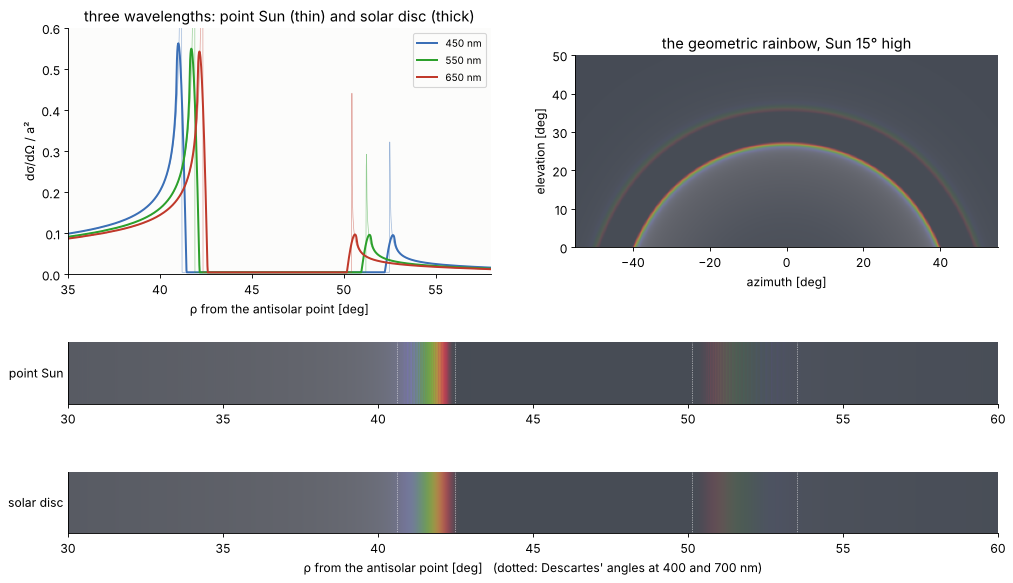

In [8]:
rho_edges = np.arange(0, 70.001, 0.02)*DEG                 # angle from the antisolar point
rho = (rho_edges[:-1] + rho_edges[1:])/2
d_omega_rho = 2*np.pi*(np.cos(rho_edges[:-1]) - np.cos(rho_edges[1:]))
b_geo = np.sqrt((np.arange(150_000) + 0.5)/150_000)       # equal area rings


def geometric_spectrum(n, orders=ORDERS):
    # binned dsigma/dOmega(rho) (unpolarized, units a^2) of all orders for index n
    out = np.zeros(len(rho))
    for k in orders:
        i = np.arcsin(b_geo)
        th = rainbow.scattering_angle(i, n, k)
        eps_s, eps_p = rainbow.fresnel_factors(i, n, k)
        h, _ = np.histogram(np.pi - th, rho_edges, weights=(eps_s + eps_p)/2)
        out += h*np.pi/len(b_geo)/d_omega_rho
    return out


I_geo = np.array([geometric_spectrum(n_drop(l)) for l in LAM])
I_geo_sun = sun_disc(rho, I_geo)
BACKGROUND = np.array([0.06, 0.07, 0.09])
gain = 0.55

fig = plt.figure(figsize=(15, 8.2))
gs = fig.add_gridspec(3, 2, height_ratios=[1.4, 0.35, 0.35], hspace=0.55)
ax = fig.add_subplot(gs[0, 0])
for l, c in ((450, "#3b6fb6"), (550, "#2ca02c"), (650, "#c0392b")):
    j = np.argmin(abs(LAM - l))
    ax.plot(rho/DEG, I_geo[j], color=c, lw=0.6, alpha=0.5)
    ax.plot(rho/DEG, I_geo_sun[j], color=c, lw=1.8, label="{:.0f} nm".format(LAM[j]))
ax.set_xlim(35, 58); ax.set_ylim(0, 0.6)
ax.set_xlabel("ρ from the antisolar point [deg]"); ax.set_ylabel("dσ/dΩ / a²")
ax.set_title("three wavelengths: point Sun (thin) and solar disc (thick)"); ax.legend(fontsize=9)
ax = fig.add_subplot(gs[0, 1])
lin = colour.xyz_to_linear_srgb(colour.spectrum_to_xyz(LAM, I_geo_sun*SUN[:, None], axis=0))
img, ext = sky_image(rho, gain*lin, sun_elevation=15.0, background=BACKGROUND)
ax.imshow(img, extent=ext, aspect="equal")
ax.set_xlabel("azimuth [deg]"); ax.set_ylabel("elevation [deg]")
ax.set_title("the geometric rainbow, Sun 15° high")
for row, (I, name) in enumerate(((I_geo, "point Sun"), (I_geo_sun, "solar disc"))):
    ax = fig.add_subplot(gs[1 + row, :])
    ax.imshow(rgb_of(I, gain, BACKGROUND)[None], extent=(0, 70, 0, 1), aspect="auto")
    ax.set_yticks([]); ax.set_xlim(30, 60)
    ax.set_ylabel(name, rotation=0, ha="right", va="center")
    for k in (1, 2):
        for l in (400, 700):
            ax.axvline(180 - rainbow.descartes(n_drop(l), k)[2]/DEG, color="w", lw=0.6, ls=":")
ax.set_xlabel("ρ from the antisolar point [deg]   (dotted: Descartes' angles at 400 and 700 nm)")

Each wavelength has a sharp peak at its Descartes angle, and the bright
side of the peak falls off slowly; the Sun's disc rounds the peaks and
shifts their maxima by a fraction of its radius. The colours are not
spectral: at every angle we see the peak of one wavelength on top of the
slowly falling tails of all longer (primary) wavelengths, which is why the
inside of the primary bow is white and brighter than the sky outside and
why the violet end of the bow is a pale, whitish blue. The red edges lie
at the Descartes angle of the red end of the spectrum.

## 5. Waves: Airy's theory against Lorenz-Mie theory

Airy integrated the cubic wavefront of section 2 in the diffraction
approximation. With the wave number $k_0 = 2\pi/\lambda$ and
$q = 2/|\theta''_c|$,

$$\frac{\mathrm d\sigma}{\mathrm d\Omega} = \frac{2\pi b_c \varepsilon_c}{\sin\theta}
  k_0^{1/3} q^{2/3}\,\mathrm{Ai}^2(z),\qquad
  z = -\operatorname{sgn}(\theta''_c)\,(\theta - \theta_c)\,k_0^{2/3}q^{1/3}$$

(`rainbow.airy_cross_section()`). It is finite, peaks on the bright side
of Descartes' angle, and continues into the **supernumerary** maxima at the
zeros $a'_m$ of $\mathrm{Ai}'$ ($-1.019, -3.248, -4.820, \ldots$), at

$$\theta_m - \theta_c = \frac{|a'_m|}{k_0^{2/3} q^{1/3}}
  \propto \left(\frac{\lambda}{a}\right)^{2/3} .$$

Averaged over the fringes, $\mathrm{Ai}^2(-z) \approx 1/(2\pi\sqrt z)$
reproduces the geometric $|\theta - \theta_c|^{-1/2}$ (both branches).
The exact answer is the Lorenz-Mie series, here
$\mathrm d\sigma/\mathrm d\Omega = |S_1|^2/k_0^2$ (s) and
$|S_2|^2/k_0^2$ (p) from `analytical.mie_amplitudes()`, which needs about
$x + 4x^{1/3}$ terms for the size parameter $x = k_0 a$ (5 700 for
$a = 0.5$ mm). Mie contains all orders at once: the interference of the
primary light with the external reflection adds a fast ripple, which is
averaged here over a ±2 % spread of drop radii.

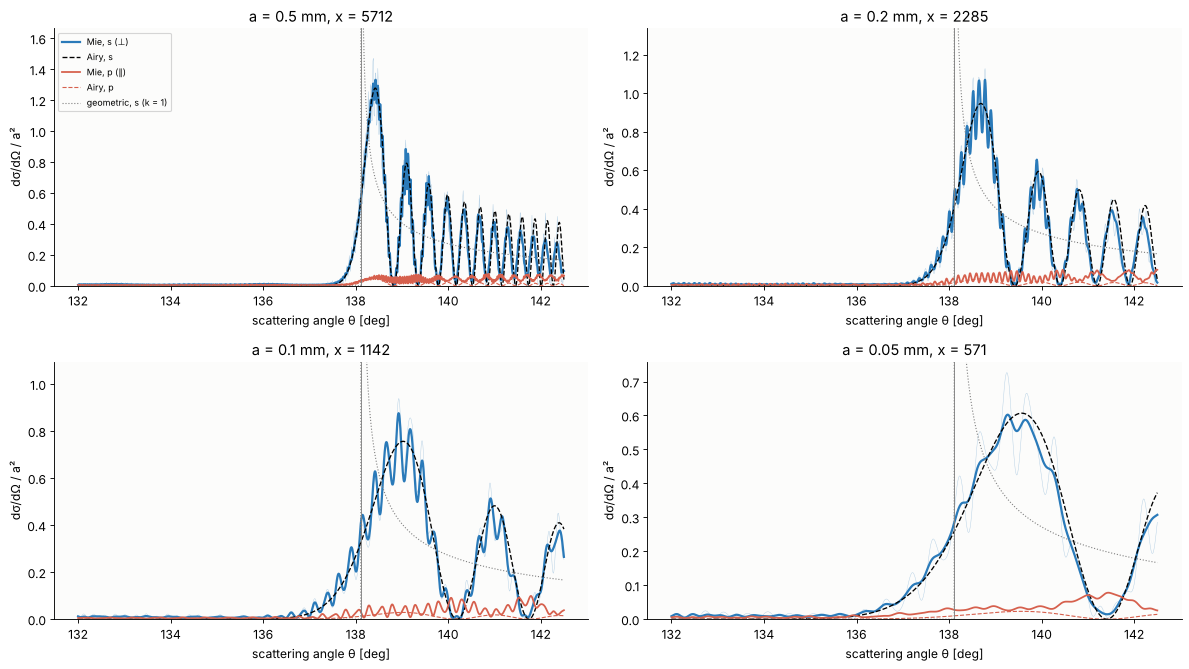

In [9]:
theta_w = np.linspace(132.0, 142.5, 1400)*DEG
radii = [0.5, 0.2, 0.1, 0.05]
fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
mie_avg = {}
for ax, a in zip(axes.flat, radii):
    spread = a*(1 + np.linspace(-0.02, 0.02, 5))
    I_s = I_p = 0
    for j, aj in enumerate(spread):
        S1, S2 = mie_amplitudes(theta_w, aj, N550, WL)
        I_s = I_s + np.abs(S1)**2/K550**2/len(spread)
        I_p = I_p + np.abs(S2)**2/K550**2/len(spread)
        if j == 2:
            ax.plot(theta_w/DEG, np.abs(S1)**2/K550**2/a**2, color="#2a7ab9", lw=0.4, alpha=0.35)
    mie_avg[a] = I_s
    A_s, A_p = rainbow.airy_cross_section(theta_w, a, WL, N550, 1)
    g_s, g_p = rainbow.geometric_cross_section(N550, 1, a, theta=theta_w)
    ax.plot(theta_w/DEG, I_s/a**2, color="#2a7ab9", lw=2, label="Mie, s (⊥)")
    ax.plot(theta_w/DEG, A_s/a**2, color="k", lw=1.2, ls="--", label="Airy, s")
    ax.plot(theta_w/DEG, I_p/a**2, color="#d6604d", lw=1.6, label="Mie, p (∥)")
    ax.plot(theta_w/DEG, A_p/a**2, color="#d6604d", lw=1.0, ls="--", label="Airy, p")
    ax.plot(theta_w/DEG, g_s/a**2, color="0.5", lw=1, ls=":", label="geometric, s (k = 1)")
    ax.axvline(rainbow.descartes(N550, 1)[2]/DEG, color="0.5", lw=0.8)
    ax.set_ylim(0, 1.25*max(I_s.max(), A_s.max())/a**2)
    ax.set_title("a = {} mm, x = {:.0f}".format(a, K550*a))
    ax.set_xlabel("scattering angle θ [deg]"); ax.set_ylabel("dσ/dΩ / a²")
axes[0, 0].legend(fontsize=8, loc="upper left")
plt.tight_layout()

For millimetre drops Airy and Mie agree on the main peak and the first
supernumeraries in position and height (s polarization, which carries 93 %
of the light); the main peak lies a little inside Descartes' angle (grey
line), on the bright side. For smaller drops the fringes move apart and
the bow broadens. Two failures of Airy's scalar theory show up:

- **p polarization:** the p-polarized light of Mie theory is weak, but
  several times stronger than Airy's (dashed red), and its fringes do not
  follow those of s. The internal reflection of the rainbow ray lies close
  to the Brewster angle, where $R_p$ changes quickly across the
  wavefront; a constant $\varepsilon_c$ cannot describe this.
- **far from the bow and for small drops:** Airy's cubic approximation of
  $\theta(b)$ holds only near the rainbow ray. The outer supernumeraries of
  Airy are too strong (0.5 mm), and for 0.1 and 0.05 mm Mie adds wiggles
  from the interference with the externally reflected light, which Airy
  leaves out (Nussenzveig's complex angular momentum theory includes
  both).

The supernumerary positions are the test of the $a^{-2/3}$ law: below,
the distance of the main maximum and the first supernumeraries from
Descartes' angle, from the averaged Mie curves (s), against Airy's
formula.

a = 0.03 mm: Mie [2.026 6.227 9.347], Airy [2.019 6.438 9.554]
a = 0.05 mm: Mie [1.193 4.568 6.633], Airy [1.436 4.58  6.796]
a = 0.08 mm: Mie [1.058 3.279 4.854], Airy [1.05  3.348 4.968]
a = 0.12 mm: Mie [0.836 2.514 3.744], Airy [0.801 2.555 3.791]
a = 0.20 mm: Mie [0.539 1.795 2.662], Airy [0.57  1.818 2.697]
a = 0.30 mm: Mie [0.438 1.369 2.032], Airy [0.435 1.387 2.058]
a = 0.50 mm: Mie [0.269 0.97  1.464], Airy [0.309 0.987 1.464]


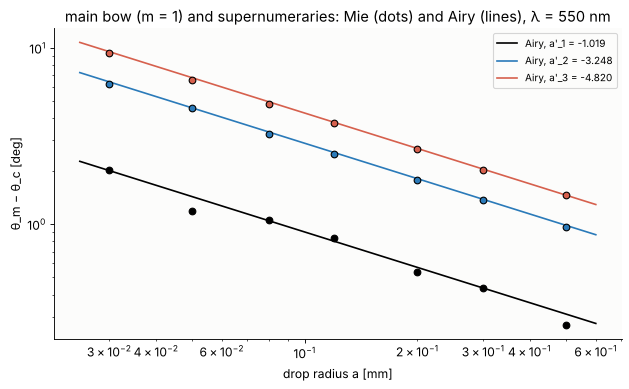

In [10]:
_, ap, _, _ = ai_zeros(3)                  # zeros a'_m of Ai'
k_c = rainbow.airy_parameters(N550, 1, 1.0)
radii_s = np.array([0.03, 0.05, 0.08, 0.12, 0.2, 0.3, 0.5])
th_c = rainbow.descartes(N550, 1)[2]
peaks = np.full((len(radii_s), 3), np.nan)
for j, a in enumerate(radii_s):
    th = np.linspace(th_c/DEG - 0.5, th_c/DEG + 10*(0.1/a)**(2/3), 1500)*DEG
    I = np.abs(mie_amplitudes(th, a, N550, WL)[0])**2
    # smooth over the ripple (period about pi/x) before looking for the maxima
    I = gaussian_filter1d(I, 2.0/(K550*a)/(th[1] - th[0]))
    pk, _ = find_peaks(I, prominence=0.1*I.max())
    pk = pk[th[pk] > th_c][:3]
    peaks[j, :len(pk)] = (th[pk] - th_c)/DEG
aa = np.geomspace(0.025, 0.6, 100)
fig, ax = plt.subplots(figsize=(8, 5))
for m, c in zip(range(3), ("k", "#2a7ab9", "#d6604d")):
    q = 2*aa**2/abs(k_c[2])
    ax.loglog(aa, -ap[m]/(K550**(2/3)*q**(1/3))/DEG, color=c, lw=1.5,
              label="Airy, a'_{} = {:.3f}".format(m + 1, ap[m]))
    ax.loglog(radii_s, peaks[:, m], "o", color=c, mec="k")
ax.set_xlabel("drop radius a [mm]"); ax.set_ylabel("θ_m − θ_c [deg]")
ax.set_title("main bow (m = 1) and supernumeraries: Mie (dots) and Airy (lines), λ = 550 nm")
ax.legend(fontsize=9)
for a, row in zip(radii_s, peaks):
    q = 2*a**2/abs(k_c[2])
    airy_pos = -ap/(K550**(2/3)*q**(1/3))/DEG
    print("a = {:.2f} mm: Mie {}, Airy {}".format(a, np.round(row, 3), np.round(airy_pos, 3)))
plt.tight_layout()

The main maximum and the supernumeraries follow $a^{-2/3}$ (the Mie
curves are smoothed over the ripple first). The supernumeraries agree with
Airy to about 3 % down to 0.03 mm, the main maximum scatters more (by up
to 0.25° around 0.05 mm, where the reflected light interferes with it). A measured fringe spacing is a measure of the drop size
(rainbow refractometry), and since rain drops of different sizes wash out
the fringes, visible supernumeraries mean drops of nearly the same size,
typically 0.2 to 0.5 mm, near the top of a bow where the small drops of a
shower fall.

## 6. The colours of real rainbows

Now the colours with wave theory: the Mie cross sections (unpolarized,
all orders in one) for each wavelength, smeared by the solar disc, for
drops from 0.25 mm down to 15 µm, compared with the geometric strip of
section 4 (large drops). The Mie series runs over 36 wavelengths and up to
4 000 terms. The brightness of each strip is scaled to the same maximum.

Mie for 36 wavelengths and 4 radii: 29 s


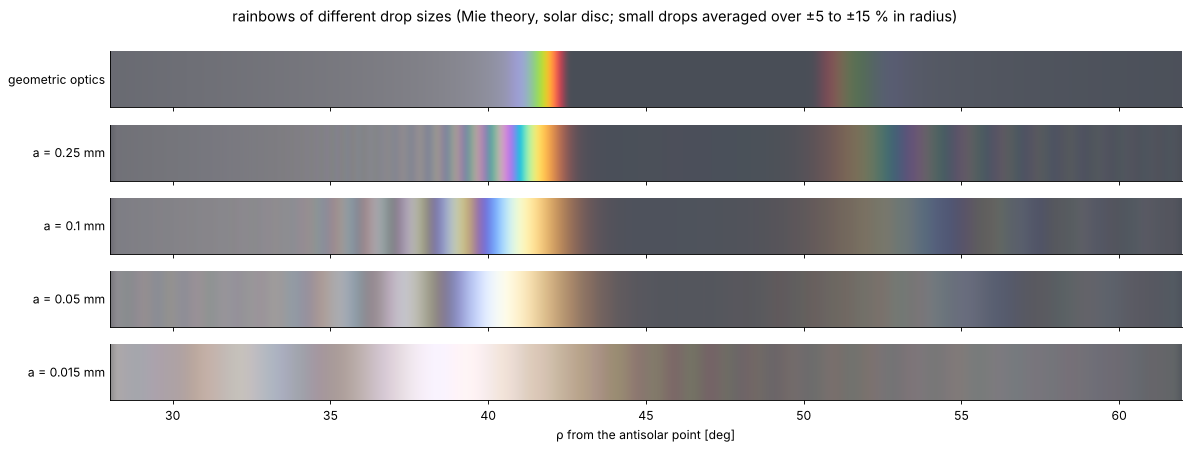

In [11]:
rho_w = np.arange(28.0, 62.0, 0.02)*DEG
theta_m = np.pi - rho_w


def mie_spectrum(a, spread=0.0, n_sizes=1):
    # unpolarized dsigma/dOmega(rho)/a^2 for all wavelengths, averaged over drop radii
    # a (1 +- spread), solar disc included
    out = np.zeros((len(LAM), len(rho_w)))
    for aj in a*(1 + np.linspace(-spread, spread, n_sizes)):
        for j, l in enumerate(LAM):
            S1, S2 = mie_amplitudes(theta_m, aj, n_drop(l), l*1e-6)
            out[j] += (np.abs(S1)**2 + np.abs(S2)**2)/2/(2*np.pi/(l*1e-6))**2/aj**2/n_sizes
    return sun_disc(rho_w, out)


t0 = time.time()
cases = {0.25: (0.0, 1), 0.1: (0.05, 3), 0.05: (0.1, 5), 0.015: (0.15, 9)}   # radius: spread, sizes
I_mie = {a: mie_spectrum(a, *sp) for a, sp in cases.items()}
print("Mie for {} wavelengths and {} radii: {:.0f} s".format(len(LAM), len(cases), time.time() - t0))
I_geo_w = np.array([np.interp(rho_w, rho, I) for I in I_geo_sun])

strips = [("geometric optics", I_geo_w)] + [("a = {:g} mm".format(a), I_mie[a]) for a in cases]
fig, axes = plt.subplots(len(strips), 1, figsize=(15, 1.0*len(strips) + 0.6), sharex=True)
for ax, (name, I) in zip(axes, strips):
    lin = colour.xyz_to_linear_srgb(colour.spectrum_to_xyz(LAM, I*SUN[:, None], axis=0))
    g = 0.95/lin.max()
    ax.imshow(rgb_of(I, g, BACKGROUND)[None], extent=(rho_w[0]/DEG, rho_w[-1]/DEG, 0, 1), aspect="auto")
    ax.set_yticks([]); ax.set_ylabel(name, rotation=0, ha="right", va="center")
axes[-1].set_xlabel("ρ from the antisolar point [deg]")
fig.suptitle("rainbows of different drop sizes (Mie theory, solar disc; small drops averaged over ±5 to ±15 % in radius)", y=1.0)
plt.tight_layout()

a =  0.250 mm: maximum at 550 nm 41.42 deg from the antisolar point, Airy 41.40 deg, Descartes 41.89 deg
a =  0.100 mm: maximum at 550 nm 40.96 deg from the antisolar point, Airy 40.98 deg, Descartes 41.89 deg
a =  0.050 mm: maximum at 550 nm 40.44 deg from the antisolar point, Airy 40.45 deg, Descartes 41.89 deg
a =  0.015 mm: maximum at 550 nm 38.86 deg from the antisolar point, Airy 38.68 deg, Descartes 41.89 deg


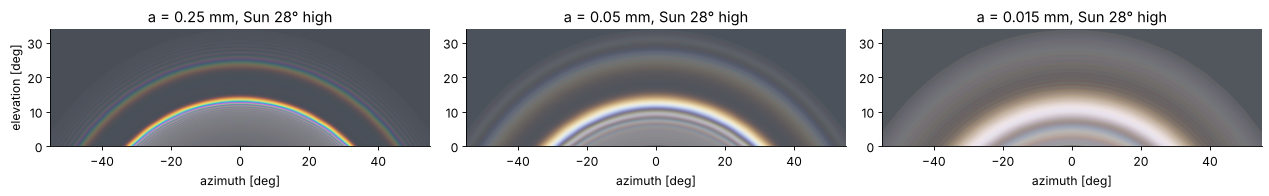

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.6))
for ax, a in zip(axes, (0.25, 0.05, 0.015)):
    I = I_mie[a]
    lin = colour.xyz_to_linear_srgb(colour.spectrum_to_xyz(LAM, I*SUN[:, None], axis=0))
    img, ext = sky_image(rho_w, 0.8*lin/lin.max(), sun_elevation=28.0, height=34,
                         background=BACKGROUND)
    ax.imshow(img, extent=ext, aspect="equal")
    ax.set_title("a = {:g} mm, Sun 28° high".format(a)); ax.set_xlabel("azimuth [deg]")
axes[0].set_ylabel("elevation [deg]")
plt.tight_layout()

# position of the brightest point at 550 nm against Airy's main maximum
j = np.argmin(abs(LAM - 550))
for a in cases:
    rho_max = rho_w[np.argmax(I_mie[a][j])]/DEG
    q = 2*a**2/abs(k_c[2])
    airy_rho = 180 - (th_c/DEG - ap[0]/(K550**(2/3)*q**(1/3))/DEG)     # ap[0] = -1.019
    print("a = {:6.3f} mm: maximum at 550 nm {:.2f} deg from the antisolar point, Airy {:.2f} deg, Descartes {:.2f} deg".format(
        a, rho_max, airy_rho, 180 - th_c/DEG))

With drops of 0.25 mm the bow is still as colourful as the geometric one,
but inside it come the pink and green supernumerary bands. At 0.05 mm
the bow is broader and paler, the colours of the main bow mix to white
with an orange outer and a blue inner rim, and the bow moves inwards: at
550 nm its maximum lies 1.4° inside Descartes' angle. Drops of 15 µm
(mist, fog, clouds) give the **fogbow**: the diffraction width of each
wavelength, a few degrees, is larger than the dispersion, the colours
overlap to white with a faint reddish rim, and it lies 3° inside the
rainbow. In all four cases the brightest point at 550 nm agrees with the
main maximum of Airy's theory to 0.2°, the shift $\propto (\lambda/a)^{2/3}$
that makes small drops' bows smaller.

## 7. The glory

From an aircraft above a cloud deck, or on a mountain with the Sun behind
and fog below, the shadow on the cloud is surrounded by coloured rings, the
**glory**, a few degrees in radius (sketch below). Further out, at about
40°, the cloud bow is a white fogbow.

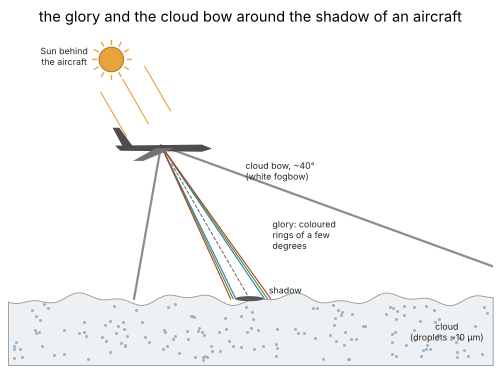

In [13]:
fig, ax = plt.subplots(figsize=(10, 4.8))
sketch.glory_aircraft(ax, title="the glory and the cloud bow around the shadow of an aircraft")
plt.tight_layout()

Geometric optics has no explanation for the glory. Straight backward
light comes only from the reflection at the front of the drop and from
rays near the axis of higher orders, which spread their power over a
large solid angle. For a backward glory ray the deviation would have to
be $180°$ for a ray that leaves near the rim, which in water
($n < \sqrt 2$) needs more refraction than the drop can give: about 14° is
missing. Van de Hulst (1947) and Nussenzveig (1969) showed that this gap is
bridged by **surface waves**, light tangent to the drop that travels along
its surface and sheds energy tangentially. Seen from the back, the
glory light then comes from a luminous ring of radius $a$ at the rim, a
source whose far field is a sum of Bessel functions: van de Hulst wrote
the backward amplitudes as $S_{1,2} \approx A J_0(u) \pm B J_2(u)$,
$u = x\sin\gamma$ ($\gamma = 180° - \theta$), so the unpolarized
intensity is $|A|^2J_0^2(u) + |B|^2J_2^2(u)$ and the rings scale with
$1/x$.

Below: the Mie series for cloud droplets of 5, 10 and 20 µm (each
averaged over ±8 % in radius, which removes the sharp resonances of single
sizes), plotted against $u = x\sin\gamma$; the geometric cross section
of all orders for comparison; and the Bessel fit for 10 µm.

fitted |B|^2/|A|^2 = 4.0
a =    5 um: rings (maxima) at u = [ 3.05  6.45  9.4  12.49]
a =   10 um: rings (maxima) at u = [ 3.09  6.52  9.58 12.67]
a =   20 um: rings (maxima) at u = [ 3.19  6.62  9.73 12.83]
maxima of J2^2: u = [ 3.05  6.71  9.97 13.17]


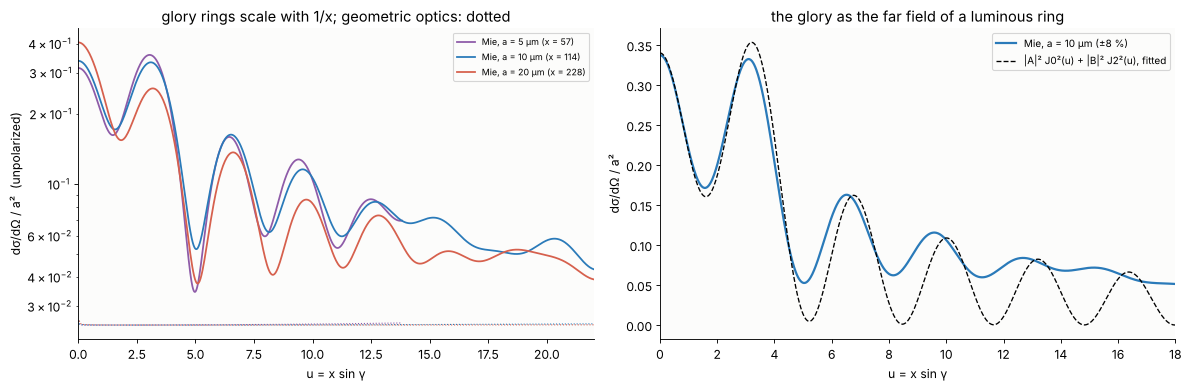

In [14]:
gamma = np.linspace(0.0, 14.0, 1401)*DEG
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
fits = {}
for a, c in zip((0.005, 0.01, 0.02), ("#8e5ba8", "#2a7ab9", "#d6604d")):
    x = K550*a
    spread = a*(1 + np.linspace(-0.08, 0.08, 17))
    I = 0
    for aj in spread:
        S1, S2 = mie_amplitudes(np.pi - gamma, aj, N550, WL)
        I = I + (np.abs(S1)**2 + np.abs(S2)**2)/2/K550**2/len(spread)
    u = x*np.sin(gamma)
    axes[0].plot(u, I/a**2, color=c, lw=1.6, label="Mie, a = {:g} µm (x = {:.0f})".format(a*1e3, x))
    geo = sum(sum(rainbow.geometric_cross_section(N550, k, a, theta=np.pi - gamma[1:]))/2
              for k in ORDERS)
    axes[0].plot(u[1:], geo/a**2, color=c, lw=1, ls=":")
    fits[a] = (u, I)
axes[0].set_xlim(0, 22); axes[0].set_yscale("log")
axes[0].set_xlabel("u = x sin γ"); axes[0].set_ylabel("dσ/dΩ / a²  (unpolarized)")
axes[0].set_title("glory rings scale with 1/x; geometric optics: dotted")
axes[0].legend(fontsize=8)

u, I = fits[0.01]
sel = u < 18
M = np.stack([jv(0, u)**2, jv(2, u)**2], 1)
coef, *_ = np.linalg.lstsq(M[sel], I[sel], rcond=None)
axes[1].plot(u, I/0.01**2, color="#2a7ab9", lw=2, label="Mie, a = 10 µm (±8 %)")
axes[1].plot(u, M @ coef/0.01**2, color="k", lw=1.2, ls="--",
             label="|A|² J0²(u) + |B|² J2²(u), fitted")
axes[1].set_xlim(0, 18); axes[1].set_xlabel("u = x sin γ"); axes[1].set_ylabel("dσ/dΩ / a²")
axes[1].set_title("the glory as the far field of a luminous ring"); axes[1].legend(fontsize=9)
print("fitted |B|^2/|A|^2 = {:.1f}".format(coef[1]/coef[0]))
for a, (u, I) in fits.items():
    pk, _ = find_peaks(I)
    print("a = {:4.0f} um: rings (maxima) at u = {}".format(a*1e3, np.round(u[pk][:4], 2)))
print("maxima of J2^2: u = {}".format(np.round([3.054, 6.706, 9.970, 13.170], 2)))
plt.tight_layout()

Near the shadow the glory is more than ten times brighter than geometric
optics allows (dotted, mostly the external reflection), and its rings fall
on top of each other when plotted against $x\sin\gamma$: the ring radius
is inversely proportional to the drop size,
$\gamma_m \approx u_m\lambda/(2\pi a)$. The first ring lies at
$u \approx 3.1$, as the first maximum of $J_2^2$ (the $B$ term dominates);
further out the rings are spaced by about 3.2, a little closer than the
Bessel maxima, and damped, and van de Hulst's two-term form only describes
the first two. For 10 µm droplets the first ring lies 1.6° from the
shadow.

Finally the glory and the cloud bow as seen from an aircraft, for cloud
droplets with a distribution of radii around 10 µm (log-normal, 12 %
width), with the solar disc:

cloud: 4 s


Text(0.5, 1.0, 'looking down at the cloud: glory and cloud bow')

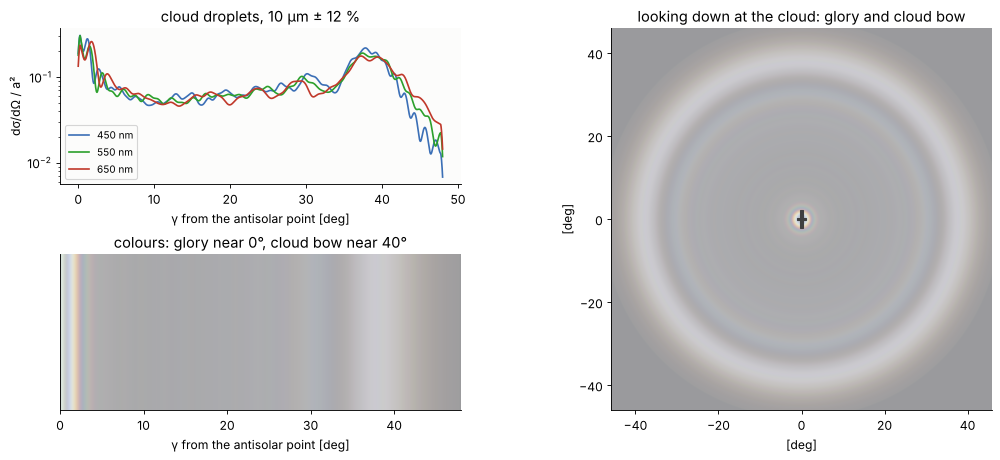

In [15]:
gam = np.arange(0.0, 48.0, 0.02)*DEG
radii_c = 0.01*np.exp(0.12*np.linspace(-2, 2, 21))
weights = np.exp(-0.5*np.linspace(-2, 2, 21)**2)*radii_c**2
weights /= weights.sum()
t0 = time.time()
I_cloud = np.zeros((len(LAM), len(gam)))
for j, l in enumerate(LAM):
    k0 = 2*np.pi/(l*1e-6)
    for a, w in zip(radii_c, weights):
        S1, S2 = mie_amplitudes(np.pi - gam, a, n_drop(l), l*1e-6)
        I_cloud[j] += w*(np.abs(S1)**2 + np.abs(S2)**2)/2/k0**2/a**2
I_cloud_sun = sun_disc(gam, I_cloud)
print("cloud: {:.0f} s".format(time.time() - t0))

lin = colour.xyz_to_linear_srgb(colour.spectrum_to_xyz(LAM, I_cloud_sun*SUN[:, None], axis=0))
cloud_white = np.array([0.30, 0.31, 0.33])       # the cloud in diffuse light
fig = plt.figure(figsize=(16, 6.2))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.25], height_ratios=[1, 1], hspace=0.45)
ax = fig.add_subplot(gs[0, 0])
for l, c in ((450, "#3b6fb6"), (550, "#2ca02c"), (650, "#c0392b")):
    j = np.argmin(abs(LAM - l))
    ax.semilogy(gam/DEG, I_cloud_sun[j], color=c, lw=1.5, label="{:.0f} nm".format(LAM[j]))
ax.set_xlabel("γ from the antisolar point [deg]"); ax.set_ylabel("dσ/dΩ / a²")
ax.set_title("cloud droplets, 10 µm ± 12 %"); ax.legend(fontsize=9)
ax = fig.add_subplot(gs[1, 0])
g = 0.5/np.max(lin[gam < 6*DEG])
strip = colour.srgb_gamma(np.clip(g*lin + cloud_white, 0, None))
ax.imshow(strip[None], extent=(0, gam[-1]/DEG, 0, 1), aspect="auto")
ax.set_yticks([]); ax.set_xlabel("γ from the antisolar point [deg]")
ax.set_title("colours: glory near 0°, cloud bow near 40°")
# view straight down along the antisolar direction
ax = fig.add_subplot(gs[:, 1])
xx = np.linspace(-46, 46, 700)
X, Y = np.meshgrid(xx, xx)
R = np.hypot(X, Y)*DEG
img = np.stack([np.interp(R, gam, c, right=c[-1]) for c in (g*lin).T], -1) + cloud_white
img = img - np.minimum(img.min(axis=-1, keepdims=True), 0)
ax.imshow(colour.srgb_gamma(img), extent=(xx[0], xx[-1], xx[0], xx[-1]))
ax.add_patch(plt.Polygon([(-1.2, -0.3), (1.2, -0.3), (1.2, 0.3), (-1.2, 0.3)], color="0.25"))
ax.add_patch(plt.Polygon([(-0.25, -2.2), (0.25, -2.2), (0.25, 2.2), (-0.25, 2.2)], color="0.25"))
ax.set_xlabel("[deg]"); ax.set_ylabel("[deg]")
ax.set_title("looking down at the cloud: glory and cloud bow")

The glory is a small bright core with coloured rings within about 4° of
the shadow, each ring red outside, as in photographs from aircraft; the
cloud bow, about 37° from the shadow, is a broad white band with a faint
bluish inner rim, and between them there is a faint white secondary
maximum around 30°. Since the ring radii scale with $\lambda/a$, the glory of a cloud
with a narrow droplet distribution shows its droplet size directly:
$a \approx u_1\lambda/(2\pi\gamma_1)$ with the first maximum $u_1 \approx 3$.

## Summary

- Descartes' minimum deviation, $\cos^2 i_c = (n^2 - 1)/(k(k+2))$, puts the
  primary bow at 42° and the secondary at 51° around the antisolar point
  (water, $n_D = 1.333$); the exact drop trace and the sequential ray
  tracer (one tilted surface per intersection) agree with it to rounding.
- The dispersion of water spreads the primary over 1.8° and the secondary
  over 3.4°, in agreement with $\mathrm dD_c/\mathrm dn = 2(k+1)\tan r_c/n$.
- The geometric intensity diverges at the caustic, where the outgoing
  wavefront is Airy's cubic; Alexander's band is 13 times darker than the
  sky 30° from the antisolar point; the bows are 93 % and 81 % polarized.
- Airy's theory agrees with Mie theory for large drops (s polarization) and
  predicts the supernumeraries with their $(\lambda/a)^{2/3}$ spacing to
  3 %, and the inward shift of the bow of small drops; it underestimates
  the p-polarized light and leaves out the ripple from the reflection.
- Small drops give broad white fogbows 3° inside the rainbow, and cloud
  droplets give the glory, rings at $u = x\sin\gamma \approx 3.1, 6.5, 9.6$
  that no ray explains.

## References

- R. Descartes, *Les Météores*, discourse 8, Leiden (1637).
- G. B. Airy, "On the intensity of light in the neighbourhood of a caustic", Trans. Camb. Phil. Soc. 6, 379-403 (1838).
- G. Mie, "Beiträge zur Optik trüber Medien, speziell kolloidaler Metallösungen", Ann. Phys. 330, 377-445 (1908).
- H. C. van de Hulst, *Light Scattering by Small Particles*, Wiley (1957), chapters 12 and 13.
- H. M. Nussenzveig, "The theory of the rainbow", Sci. Am. 236(4), 116-127 (1977).
- H. M. Nussenzveig, "Light tunneling in clouds", Appl. Opt. 42, 1588-1593 (2003).
- J. A. Adam, "The mathematical physics of rainbows and glories", Phys. Rep. 356, 229-365 (2002).
- C. F. Bohren and D. R. Huffman, *Absorption and Scattering of Light by Small Particles*, Wiley (1983).
- R. L. Lee, "Mie theory, Airy theory, and the natural rainbow", Appl. Opt. 37, 1506-1519 (1998).
- G. P. Können, *Polarized Light in Nature*, Cambridge University Press (1985).
- P. Laven, "Simulation of rainbows, coronas, and glories by use of Mie theory", Appl. Opt. 42, 436-444 (2003).
- M. Daimon and A. Masumura, "Measurement of the refractive index of distilled water from the near-infrared region to the ultraviolet region", Appl. Opt. 46, 3811-3820 (2007).
- P. E. Ciddor, "Refractive index of air: new equations for the visible and near infrared", Appl. Opt. 35, 1566-1573 (1996).
- C. Wyman, P.-P. Sloan and P. Shirley, "Simple analytic approximations to the CIE XYZ color matching functions", J. Comput. Graph. Tech. 2, 1-11 (2013).

In [16]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 61 s
